# Fase C: Modelos de Machine Learning

## Diseño

Se hace una comparacion con Regresion Logistica, Arbol de Decision y Random Forest, ademas de una ponderacion de clases. Se informa Accuracy, Precision, Recall, F1 de clase positiva y matrices de confusion. Se selecciona por F1 positivo, considerando tambien precision y recall. Se realiza `train_test_split` estratificado 80/20; el escalado de Regresion Logistica se ajusta dentro de Pipeline y solamente con entrenamiento. K-Means segmenta predictores sin emplear la etiqueta; Silhouette y Davies-Bouldin se calculan en una muestra de prueba.

**Limitacion heredada:** el parquet ya contiene imputaciones y One-Hot hechos en B antes de dividir los datos. En C no se puede deshacer ese procesamiento desde el parquet; el escalado y los modelos si se ajustan despues del split. Para prevenir tambien cualquier fuga por imputacion, B tendria que exportar datos antes de imputar y C ajustar el imputador dentro del pipeline.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, davies_bouldin_score, f1_score, precision_score, recall_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TARGET = "con_victimas"
CANDIDATES = [Path("datos_limpios.parquet"), Path("entrega/datos_limpios.parquet"), Path("p2p3/entrega/datos_limpios.parquet"), Path("../entrega/datos_limpios.parquet")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("No se encontro datos_limpios.parquet. Rutas probadas: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
data = pd.read_parquet(DATA_PATH)
required = {TARGET, "id_siniestro", "fecha"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing)}")
if data[TARGET].isna().any() or set(data[TARGET].unique()) != {0, 1}:
    raise ValueError("El objetivo debe estar completo y contener clases 0 y 1.")
if not data["id_siniestro"].is_unique:
    raise ValueError("id_siniestro contiene duplicados.")
print(f"Parquet: {DATA_PATH.resolve()} | filas: {len(data):,} | columnas: {data.shape[1]}")
display(data[TARGET].value_counts(normalize=True).sort_index().rename("proporcion").to_frame())

Parquet: C:\Users\ACER NITRO V16\Documents\Ciencia de Datos\Proyecto1\Ciencias-de-datos\p2p3\entrega\datos_limpios.parquet | filas: 370,998 | columnas: 38


,proporcion
con_victimas,
0,0.862905
1,0.137095


## 1. Preparacion y split

Se eliminan del conjunto de predictores el objetivo, el identificador y la fecha original. Las variables temporales derivadas en B se conservan. Se comprueba la ausencia de nulos, infinitos y columnas no numericas. No se escala antes de la separacion.

In [2]:
X = data.drop(columns=[TARGET, "id_siniestro", "fecha"])
y = data[TARGET].astype("int8")
non_numeric = X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()
if non_numeric:
    raise TypeError(f"Hay predictores no numericos: {non_numeric}")
if X.isna().any().any():
    raise ValueError(f"Quedan nulos en predictores: {X.columns[X.isna().any()].tolist()}")
if not np.isfinite(X.to_numpy(dtype="float64")).all():
    raise ValueError("Hay valores infinitos en los predictores.")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
print(f"Entrenamiento: {len(X_train):,} | prueba: {len(X_test):,} | predictores: {X.shape[1]}")
display(pd.DataFrame({"entrenamiento": y_train.value_counts(normalize=True).sort_index(), "prueba": y_test.value_counts(normalize=True).sort_index()}))

Entrenamiento: 296,798 | prueba: 74,200 | predictores: 35


,entrenamiento,prueba
con_victimas,,
0,0.862903,0.862911
1,0.137097,0.137089


## 2. Entrenamiento y evaluacion supervisada

Regresion Logistica es la referencia lineal; el arbol y el bosque aleatorio capturan relaciones no lineales. class_weight contrarresta el desbalance. Todos los modelos se ajustan solo con entrenamiento y se comparan solo en el conjunto de prueba. Se usa F1 de clase 1 como criterio de seleccion, verificando sus componentes precision y recall.

Entrenado: Regresion Logistica
Entrenado: Arbol de Decision
Entrenado: Random Forest


,Modelo,Accuracy,Precision clase 1,Recall clase 1,F1 clase 1
0,Random Forest,0.8365,0.4465,0.8037,0.5741
1,Arbol de Decision,0.8366,0.4465,0.8003,0.5732
2,Regresion Logistica,0.8383,0.4467,0.7517,0.5604


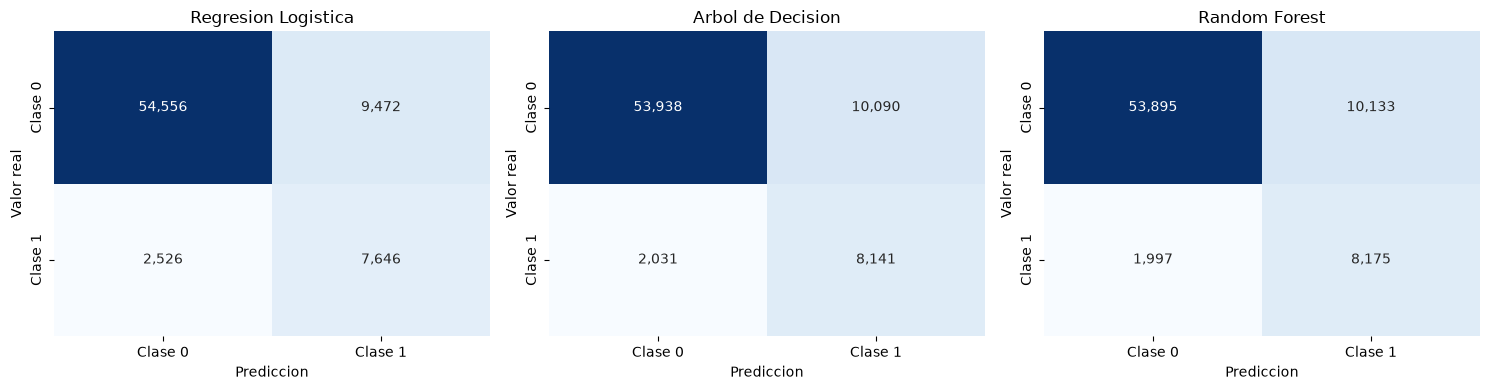

Seleccionado por F1 clase 1: Random Forest
Matrices: filas = clase real [0,1], columnas = clase predicha [0,1].


In [3]:
models = {
    "Regresion Logistica": Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))]),
    "Arbol de Decision": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=160, max_depth=18, min_samples_leaf=10, max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print("Entrenado:", name)

predictions = {}
confusion_matrices = {}
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    confusion_matrices[name] = confusion_matrix(y_test, pred, labels=[0, 1])
    rows.append({"Modelo": name, "Accuracy": accuracy_score(y_test, pred), "Precision clase 1": precision_score(y_test, pred, pos_label=1, zero_division=0), "Recall clase 1": recall_score(y_test, pred, pos_label=1, zero_division=0), "F1 clase 1": f1_score(y_test, pred, pos_label=1, zero_division=0)})
results = pd.DataFrame(rows).sort_values(["F1 clase 1", "Recall clase 1"], ascending=False).reset_index(drop=True)
display(results.style.format({c: "{:.4f}" for c in results.columns if c != "Modelo"}))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, xticklabels=["Clase 0", "Clase 1"], yticklabels=["Clase 0", "Clase 1"], ax=ax)
    ax.set(title=name, xlabel="Prediccion", ylabel="Valor real")
plt.tight_layout()
plt.show()
selected_model = results.iloc[0]["Modelo"]
print("Seleccionado por F1 clase 1:", selected_model)
print("Matrices: filas = clase real [0,1], columnas = clase predicha [0,1].")

## 3. Segmentacion con K-Means

La segmentacion usa variables de tiempo, tipo de vehiculo y caracteristicas del evento, sin incluir `con_victimas`. StandardScaler y K-Means se ajustan unicamente con entrenamiento. Para evaluar sobre prueba, se obtiene una muestra reproducible de hasta 5.000 filas. Silhouette mas alto y Davies-Bouldin mas bajo indican mejor separacion.

In [4]:
cluster_columns = ["anio", "mes", "es_fin_de_semana", "es_interseccion", "numero_vehiculos_transf", "categoria_siniestro_ord", "involucra_motocicleta", "involucra_liviano", "involucra_pesado", "involucra_no_motorizado"]
cluster_columns += sorted(c for c in X.columns if c.startswith("dia_semana_"))
missing_cluster = set(cluster_columns) - set(X.columns)
if missing_cluster:
    raise ValueError(f"Faltan variables para clustering: {sorted(missing_cluster)}")
X_train_cluster = X_train[cluster_columns].astype("float64")
X_test_cluster = X_test[cluster_columns].astype("float64")
cluster_scaler = StandardScaler()
X_train_scaled = cluster_scaler.fit_transform(X_train_cluster)
X_test_scaled = cluster_scaler.transform(X_test_cluster)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_train_scaled)
clusters_test = kmeans.predict(X_test_scaled)
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(5000, len(X_test_scaled))
sample_idx = rng.choice(len(X_test_scaled), size=sample_size, replace=False)
X_sample, labels_sample = X_test_scaled[sample_idx], clusters_test[sample_idx]
if np.unique(labels_sample).size < 2:
    raise ValueError("La muestra de prueba contiene menos de dos clusters.")
cluster_scores = pd.DataFrame({"Metrica": ["Silhouette Score", "Davies-Bouldin"], "Valor": [silhouette_score(X_sample, labels_sample), davies_bouldin_score(X_sample, labels_sample)]})
print(f"K-Means k=4; entrenado con {len(X_train_cluster):,}; metricas sobre {sample_size:,} filas de prueba")
display(cluster_scores.style.format({"Valor": "{:.4f}"}))
profile = X_test_cluster.copy()
profile["cluster"] = clusters_test
display(profile.groupby("cluster").agg(registros=("anio", "size"), anio_promedio=("anio", "mean"), vehiculos_promedio=("numero_vehiculos_transf", "mean"), fin_de_semana=("es_fin_de_semana", "mean"), interseccion=("es_interseccion", "mean"), motocicleta=("involucra_motocicleta", "mean"), liviano=("involucra_liviano", "mean"), pesado=("involucra_pesado", "mean")).round(3))

K-Means k=4; entrenado con 296,798; metricas sobre 5,000 filas de prueba


,Metrica,Valor
0,Silhouette Score,0.1812
1,Davies-Bouldin,1.7531


,registros,anio_promedio,vehiculos_promedio,fin_de_semana,interseccion,motocicleta,liviano,pesado
cluster,,,,,,,,
0,42265,2018.867,1.107,0.000,0.460,0.174,0.324,0.090
1,10531,2018.866,1.106,0.000,0.455,0.172,0.327,0.091
2,3819,2018.918,0.693,0.292,0.406,0.388,0.249,0.115
3,17585,2018.832,1.107,1.000,0.447,0.173,0.300,0.070


## 4. Conclusion y limitaciones

La tabla selecciona el modelo con mayor F1 para victimas, considerando precision, recall y falsos negativos/positivos en la matriz. El resultado es una comparacion sobre prueba; no implica causalidad ni asegura desempeno futuro. Los clusters son segmentos exploratorios y deben describirse a partir de sus perfiles, no como niveles de riesgo. La mezcla de reportes negativos, los cambios de completitud por ano y la imputacion anterior al split limitan la interpretacion. Como mejora futura, conservar datos sin imputar desde B y ajustar imputacion/codificacion dentro de pipelines despues del split.